# Praktikum 4 - Klasifikasi Citra Wajah

**Nama:** Radit Firansah  
**NIM:** 244107020196

Klasifikasi citra wajah publik figur menggunakan PCA dan SVM dengan GridSearch hyperparameter.

## Langkah 0 - Unduh Dataset

Dataset yang digunakan dapat diunduh secara langsung melalui scikit-learn.

In [1]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


## Langkah 1 - Inspeksi Citra Wajah

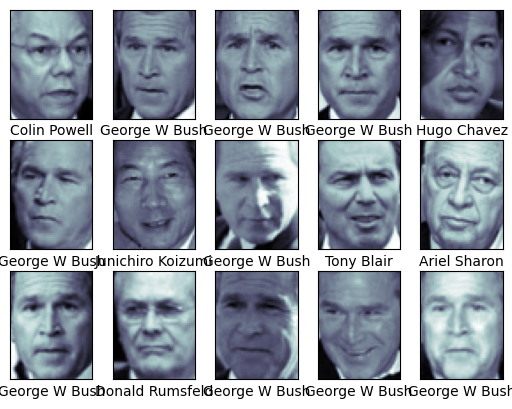

In [2]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

## Langkah 2 - Pra Pengolahan Data

PCA memproyeksikan fitur berdimensi tinggi ke dalam principal component atau fitur yang dianggap penting saja.

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

## Langkah 3 - Split Data

In [4]:
# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

## Langkah 4 - Pembuatan Model + Tunning

> **Catatan:** Agar GridSearch tidak terlalu lama, digunakan `n_jobs=-1` (paralel seluruh core) dan `cv=3` (3-fold cross-validation). Grid hyperparameter tetap sama seperti jobsheet.

In [5]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid, n_jobs=-1, cv=3)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 7.44 s, sys: 47.2 ms, total: 7.49 s
Wall time: 4.25 s
{'svc__C': 1, 'svc__gamma': 0.005}
0.8100890207715133


Gunakan model terbaik tersebut untuk proses prediksi.

In [6]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

## Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

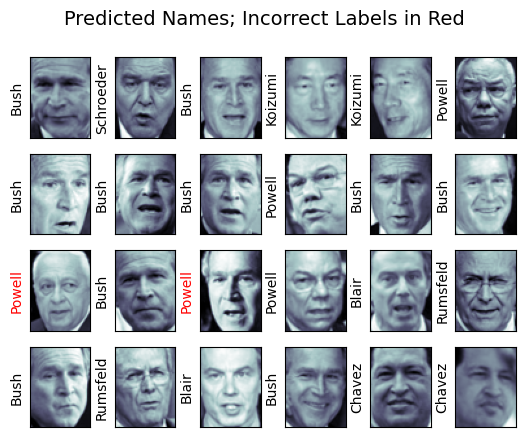

In [7]:
# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

## Langkah 6 - Cek Performansi

Pertama, cek performansi dengan `classification_report` dari sklearn.

In [8]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.92      0.80      0.86        15
     Colin Powell       0.74      0.94      0.83        68
  Donald Rumsfeld       0.83      0.81      0.82        31
    George W Bush       0.96      0.87      0.92       126
Gerhard Schroeder       0.83      0.83      0.83        23
      Hugo Chavez       1.00      0.75      0.86        20
Junichiro Koizumi       1.00      0.92      0.96        12
       Tony Blair       0.87      0.93      0.90        42

         accuracy                           0.88       337
        macro avg       0.89      0.86      0.87       337
     weighted avg       0.89      0.88      0.88       337



Selanjutnya, gunakan confusion matrix untuk mengetahui label yang terklasifikasi dengan benar dan tidak.

Text(113.92222222222219, 0.5, 'predicted label')

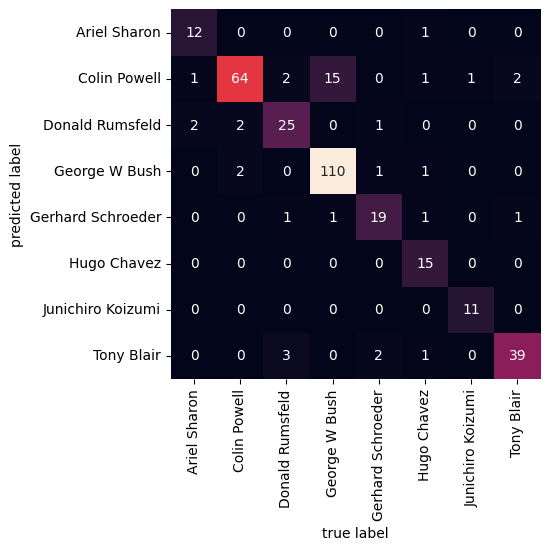

In [9]:
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')